# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [1]:
import time

NOTEBOOK_START_TIME = time.perf_counter()

print("Full notebook execution timer started.")

Full notebook execution timer started.


In [2]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Connect to 'enterprise_database.db'
# 2. Write a SQL query (using Window Functions or Subqueries) to get the most
#    recent status for each user.
# 3. Only keep users whose latest status is 'Active'.
# 4. Load the result into a Pandas DataFrame called 'df_active_users'.

# [WRITE YOUR SQL AND PYTHON CODE HERE]

In [3]:

# ================================================================
# PHASE 1: SQL CUSTOMER EXTRACTION
# Project: Enterprise Data Reconciliation
# ================================================================

import sqlite3
import pandas as pd
from pathlib import Path

# ------------------------------------------------
# 1. DATABASE FILE PATH
# ------------------------------------------------

DB_PATH = Path("enterprise_database.db")

if not DB_PATH.is_file():
    raise FileNotFoundError(
        f"Database not found: {DB_PATH.resolve()}\n"
        "Make sure the database is inside the project folder."
    )

# ------------------------------------------------
# 2. CONNECT TO SQLITE DATABASE (READ ONLY)
# ------------------------------------------------

database_uri = f"{DB_PATH.resolve().as_uri()}?mode=ro"

connection = sqlite3.connect(
    database_uri,
    uri=True
)

try:

    # ------------------------------------------------
    # 3. INSPECT AVAILABLE DATABASE TABLES
    # ------------------------------------------------

    tables = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name;
        """,
        connection
    )

    print("DATABASE TABLES")
    display(tables)

    if "users" not in tables["name"].tolist():
        raise ValueError("Required table 'users' was not found.")

    # ------------------------------------------------
    # 4. INSPECT THE USERS TABLE STRUCTURE
    # ------------------------------------------------

    users_schema = pd.read_sql_query(
        "PRAGMA table_info(users);",
        connection
    )

    print("\nUSERS TABLE STRUCTURE")
    display(users_schema)

    required_columns = {
        "user_id", "name", "status", "updated_at"
    }

    actual_columns = set(users_schema["name"])
    missing_columns = required_columns - actual_columns

    if missing_columns:
        raise ValueError(
            f"Required columns are missing: {missing_columns}"
        )

    # ------------------------------------------------
    # 5. PROFILE THE SOURCE DATABASE
    # ------------------------------------------------

    source_stats = pd.read_sql_query(
        """
        SELECT
            COUNT(*) AS total_records,

            COUNT(
                DISTINCT NULLIF(TRIM(user_id), '')
            ) AS unique_customers,

            SUM(
                CASE
                    WHEN user_id IS NULL
                      OR TRIM(user_id) = ''
                    THEN 1 ELSE 0
                END
            ) AS missing_user_ids,

            SUM(
                CASE
                    WHEN name IS NULL
                      OR TRIM(name) = ''
                    THEN 1 ELSE 0
                END
            ) AS missing_names,

            SUM(
                CASE
                    WHEN status IS NULL
                      OR TRIM(status) = ''
                    THEN 1 ELSE 0
                END
            ) AS missing_statuses,

            SUM(
                CASE
                    WHEN updated_at IS NULL
                      OR datetime(updated_at) IS NULL
                    THEN 1 ELSE 0
                END
            ) AS missing_or_invalid_dates

        FROM users;
        """,
        connection
    )

    print("\nSOURCE DATABASE STATISTICS")
    display(source_stats)

    # ------------------------------------------------
    # 6. IDENTIFY THE LATEST STATUS FOR EACH CUSTOMER
    # ------------------------------------------------

    latest_status_query = """
        WITH ranked_users AS
        (
            SELECT
                user_id,
                status,

                ROW_NUMBER() OVER
                (
                    PARTITION BY user_id

                    ORDER BY
                        datetime(updated_at) DESC,
                        rowid DESC
                ) AS rn

            FROM users

            WHERE user_id IS NOT NULL
              AND TRIM(user_id) <> ''
        )

        SELECT
            status,
            COUNT(*) AS customer_count

        FROM ranked_users

        WHERE rn = 1

        GROUP BY status

        ORDER BY status;
    """

    latest_status_summary = pd.read_sql_query(
        latest_status_query,
        connection
    )

    print("\nLATEST CUSTOMER STATUS DISTRIBUTION")
    display(latest_status_summary)

    # ------------------------------------------------
    # 7. EXTRACT ONLY CURRENTLY ACTIVE CUSTOMERS
    # ------------------------------------------------

    active_users_query = """
        WITH ranked_users AS
        (
            SELECT
                user_id,
                name,
                status,
                updated_at,

                ROW_NUMBER() OVER
                (
                    PARTITION BY user_id

                    ORDER BY
                        datetime(updated_at) DESC,
                        rowid DESC
                ) AS rn

            FROM users

            WHERE user_id IS NOT NULL
              AND TRIM(user_id) <> ''
        )

        SELECT
            user_id,
            name,
            status,
            updated_at

        FROM ranked_users

        WHERE rn = 1
          AND status = 'Active'

        ORDER BY user_id;
    """

    df_active_users = pd.read_sql_query(
        active_users_query,
        connection
    )

finally:
    connection.close()

# ------------------------------------------------
# 8. CONVERT THE UPDATE DATE TO DATETIME
# ------------------------------------------------

df_active_users["updated_at"] = pd.to_datetime(
    df_active_users["updated_at"],
    errors="coerce"
)

# ------------------------------------------------
# 9. VALIDATE THE EXTRACTED DATA
# ------------------------------------------------

assert df_active_users["user_id"].is_unique, (
    "Duplicate customer IDs were found!"
)

assert df_active_users["status"].eq("Active").all(), (
    "Non-active customers were found!"
)

active_from_summary = latest_status_summary.loc[
    latest_status_summary["status"].eq("Active"),
    "customer_count"
].sum()

assert len(df_active_users) == active_from_summary, (
    "Active customer counts do not match!"
)

assert (
    latest_status_summary["customer_count"].sum()
    == source_stats.loc[0, "unique_customers"]
), "Latest customer totals do not match unique customer IDs!"

# ------------------------------------------------
# 10. DISPLAY PHASE 1 RESULTS
# ------------------------------------------------

print("\n" + "=" * 55)
print("PHASE 1: SQL CUSTOMER EXTRACTION RESULTS")
print("=" * 55)

print(
    "Total database records:",
    source_stats.loc[0, "total_records"]
)

print(
    "Unique customers:",
    source_stats.loc[0, "unique_customers"]
)

print(
    "Active customers extracted:",
    len(df_active_users)
)

print(
    "Unique active customer IDs:",
    df_active_users["user_id"].nunique()
)

print(
    "Duplicate customer IDs:",
    df_active_users["user_id"].duplicated().sum()
)

print(
    "All extracted customers are Active:",
    df_active_users["status"].eq("Active").all()
)

print("\nFIRST 10 ACTIVE CUSTOMERS")

display(df_active_users.head(10))

print("\nPHASE 1 COMPLETED SUCCESSFULLY!")


DATABASE TABLES


,name
0,users



USERS TABLE STRUCTURE


,cid,name,type,notnull,dflt_value,pk
0,0,user_id,TEXT,0,None,0
1,1,name,TEXT,0,None,0
2,2,status,TEXT,0,None,0
3,3,updated_at,TIMESTAMP,0,None,0



SOURCE DATABASE STATISTICS


,total_records,unique_customers,missing_user_ids,missing_names,missing_statuses,missing_or_invalid_dates
0,47464,25000,0,0,0,0



LATEST CUSTOMER STATUS DISTRIBUTION


,status,customer_count
0,Active,14183
1,Pending,5935
2,Suspended,4882



PHASE 1: SQL CUSTOMER EXTRACTION RESULTS
Total database records: 47464
Unique customers: 25000
Active customers extracted: 14183
Unique active customer IDs: 14183
Duplicate customer IDs: 0
All extracted customers are Active: True

FIRST 10 ACTIVE CUSTOMERS


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00
5,U-00008,User_U-00008,Active,2023-01-27 14:00:00
6,U-00011,User_U-00011,Active,2023-01-27 14:00:00
7,U-00015,User_U-00015,Active,2023-01-02 14:00:00
8,U-00017,User_U-00017,Active,2023-01-16 14:00:00
9,U-00019,User_U-00019,Active,2023-01-22 14:00:00



PHASE 1 COMPLETED SUCCESSFULLY!


In [4]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load 'server_logs.txt' into a DataFrame.
# 2. Drop any rows where the log contains the word "ERROR".
# 3. Use Pandas string methods (.str.extract()) or Python Regex to pull the
#    Date, User ID, Product ID, and Euro Value out of the raw text string.
# 4. Save this cleaned data to a new DataFrame called 'extracted_data'.


In [5]:


# ================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# Project: Enterprise Data Reconciliation
# ================================================================

import pandas as pd
from pathlib import Path

# ------------------------------------------------
# 1. DEFINE THE SERVER LOG FILE PATH
# ------------------------------------------------

LOG_PATH = Path("server_logs.txt")

if not LOG_PATH.is_file():
    raise FileNotFoundError(
        f"Server log file not found: {LOG_PATH.resolve()}\n"
        "Check whether server_logs.txt is inside the project folder."
    )

# ------------------------------------------------
# 2. LOAD THE SERVER LOG FILE
# ------------------------------------------------
# The supplied file has one CSV-style column named
# Raw_Server_Log. Pandas decodes the escaped quotes.

logs_df = pd.read_csv(
    LOG_PATH,
    dtype="string",
    encoding="utf-8",
    keep_default_na=False
)

if logs_df.columns.tolist() != ["Raw_Server_Log"]:
    raise ValueError(
        "Unexpected server-log structure. "
        f"Found columns: {logs_df.columns.tolist()}"
    )

raw_logs = logs_df["Raw_Server_Log"].str.strip()

if raw_logs.eq("").any():
    raise ValueError("Blank server-log records require investigation.")

# ------------------------------------------------
# 3. CLASSIFY THE SERVER LOG EVENTS
# ------------------------------------------------

error_mask = raw_logs.str.contains(
    r"\bERROR\b",
    case=False,
    na=False
)

info_mask = raw_logs.str.contains(
    r"\bINFO\b",
    case=False,
    na=False
)

overlap_mask = error_mask & info_mask
unclassified_mask = ~(error_mask | info_mask)

total_log_records = len(raw_logs)
error_count = int(error_mask.sum())
info_count = int(info_mask.sum())
unclassified_count = int(unclassified_mask.sum())

print("SERVER LOG CLASSIFICATION")
print("-" * 45)
print("Total log records:", total_log_records)
print("Successful INFO events:", info_count)
print("Failed ERROR events:", error_count)
print("Unclassified events:", unclassified_count)
print("Overlapping classifications:", int(overlap_mask.sum()))

# Do not silently ignore unexpected event types.

if overlap_mask.any():
    raise ValueError(
        "Some records contain both INFO and ERROR labels."
    )

if unclassified_count > 0:
    print("\nUNCLASSIFIED LOG SAMPLES")
    display(raw_logs.loc[unclassified_mask].head(10))

    raise ValueError(
        "Unclassified log records require investigation."
    )

# ------------------------------------------------
# 4. EXCLUDE FAILED TRANSACTIONS
# ------------------------------------------------

successful_logs = raw_logs.loc[
    info_mask & ~error_mask
].copy()

print(
    "\nSuccessful records retained:",
    len(successful_logs)
)

# ------------------------------------------------
# 5. EXTRACT TRANSACTION FIELDS USING REGEX
# ------------------------------------------------

# Extract transaction date.

date_fields = successful_logs.str.extract(
    r"^\[(?P<Date>\d{4}-\d{2}-\d{2} "
    r"\d{2}:\d{2}:\d{2})\]"
)

# Extract customer ID.

user_fields = successful_logs.str.extract(
    r'"u"\s*:\s*"(?P<User_ID>U-\d+)"'
)

# Extract product ID.

product_fields = successful_logs.str.extract(
    r'"item_code"\s*:\s*"(?P<Product_ID>PRD-\d+)"'
)

# Extract successful transaction amount in EUR.

euro_fields = successful_logs.str.extract(
    r'"eur_val"\s*:\s*(?P<Euro_Value>\d+(?:\.\d+)?)'
)

# ------------------------------------------------
# 6. COMBINE THE EXTRACTED FIELDS
# ------------------------------------------------

parsed_fields = pd.concat(
    [
        date_fields,
        user_fields,
        product_fields,
        euro_fields
    ],
    axis=1
)

# ------------------------------------------------
# 7. CHECK FOR UNPARSED SUCCESSFUL LOG RECORDS
# ------------------------------------------------

parse_error_mask = parsed_fields.isna().any(axis=1)

parse_error_count = int(parse_error_mask.sum())

if parse_error_count > 0:

    print("\nUNPARSED SUCCESSFUL LOG SAMPLES")

    display(
        successful_logs.loc[parse_error_mask].head(10)
    )

    raise ValueError(
        f"{parse_error_count} successful log records "
        "could not be parsed completely."
    )

# ------------------------------------------------
# 8. CREATE THE REQUIRED extracted_data DATAFRAME
# ------------------------------------------------

extracted_data = parsed_fields.rename(
    columns={
        "User_ID": "User ID",
        "Product_ID": "Product ID",
        "Euro_Value": "Euro Value"
    }
).reset_index(drop=True)

# ------------------------------------------------
# 9. CONVERT COLUMNS INTO CORRECT DATA TYPES
# ------------------------------------------------

extracted_data["Date"] = pd.to_datetime(
    extracted_data["Date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

extracted_data["Euro Value"] = pd.to_numeric(
    extracted_data["Euro Value"],
    errors="coerce"
)

# ------------------------------------------------
# 10. VALIDATE THE EXTRACTED TRANSACTIONS
# ------------------------------------------------

assert len(extracted_data) == info_count, (
    "Successful log count and extracted transaction "
    "count do not match."
)

assert extracted_data.notna().all().all(), (
    "Missing values found in extracted transaction fields."
)

assert extracted_data["Date"].dtype.kind == "M", (
    "Date column is not in datetime format."
)

assert extracted_data["Euro Value"].dtype.kind == "f", (
    "Euro Value column is not numeric."
)

assert extracted_data["User ID"].str.match(
    r"^U-\d+$"
).all(), "Invalid customer IDs found."

assert extracted_data["Product ID"].str.match(
    r"^PRD-\d+$"
).all(), "Invalid product IDs found."

# ------------------------------------------------
# 11. ADDITIONAL DATA QUALITY CHECKS
# ------------------------------------------------

unique_transaction_customers = (
    extracted_data["User ID"].nunique()
)

unique_products = (
    extracted_data["Product ID"].nunique()
)

exact_duplicate_records = (
    extracted_data.duplicated().sum()
)

earliest_transaction = (
    extracted_data["Date"].min()
)

latest_transaction = (
    extracted_data["Date"].max()
)

# ------------------------------------------------
# 12. DISPLAY PHASE 2 RESULTS
# ------------------------------------------------

print("\n" + "=" * 55)
print("PHASE 2: REGEX EXTRACTION RESULTS")
print("=" * 55)

print("Total raw log records:", total_log_records)
print("ERROR records excluded:", error_count)
print("Successful INFO records:", info_count)
print("Unclassified records:", unclassified_count)
print("Parsing failures:", parse_error_count)

print(
    "Extracted transactions:",
    len(extracted_data)
)

print(
    "Unique transaction customers:",
    unique_transaction_customers
)

print(
    "Unique products:",
    unique_products
)

print(
    "Exact duplicate transaction rows:",
    exact_duplicate_records
)

print(
    "Earliest transaction:",
    earliest_transaction
)

print(
    "Latest transaction:",
    latest_transaction
)

print("\nEXTRACTED DATAFRAME STRUCTURE")

extracted_data.info()

print("\nFIRST 10 SUCCESSFUL TRANSACTIONS")

display(extracted_data.head(10))

print("\nPHASE 2 COMPLETED SUCCESSFULLY!")


SERVER LOG CLASSIFICATION
---------------------------------------------
Total log records: 100000
Successful INFO events: 94902
Failed ERROR events: 5098
Unclassified events: 0
Overlapping classifications: 0

Successful records retained: 94902

PHASE 2: REGEX EXTRACTION RESULTS
Total raw log records: 100000
ERROR records excluded: 5098
Successful INFO records: 94902
Unclassified records: 0
Parsing failures: 0
Extracted transactions: 94902
Unique transaction customers: 24466
Unique products: 900
Exact duplicate transaction rows: 0
Earliest transaction: 2023-01-01 00:00:00
Latest transaction: 2023-12-31 00:00:00

EXTRACTED DATAFRAME STRUCTURE
<class 'pandas.DataFrame'>
RangeIndex: 94902 entries, 0 to 94901
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        94902 non-null  datetime64[us]
 1   User ID     94902 non-null  string        
 2   Product ID  94902 non-null  string        
 3   Euro Valu

,Date,User ID,Product ID,Euro Value
0,2023-03-15,U-19484,PRD-874,3404.44
1,2023-05-09,U-18932,PRD-905,3406.21
2,2023-10-21,U-15882,PRD-284,164.08
3,2023-01-10,U-22781,PRD-665,26.8
4,2023-05-23,U-13348,PRD-589,4964.77
5,2023-10-20,U-22062,PRD-363,48.63
6,2023-12-02,U-22146,PRD-223,960.6
7,2023-03-21,U-08211,PRD-741,1129.34
8,2023-09-23,U-20854,PRD-315,2139.44
9,2023-08-04,U-11746,PRD-893,1529.29



PHASE 2 COMPLETED SUCCESSFULLY!


In [6]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
# 2. Handle the missing weekend data using a method like .fillna(method='ffill')
#    so Friday's rate rolls over to Saturday and Sunday.
# 3. Merge your cleaned logs with the exchange rates by Date.
# 4. Merge that result with your active SQL users by User ID.
# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate).
# 6. Save the final merged table as 'df_final'.

# [WRITE YOUR MERGING AND MATH CODE HERE]


In [7]:

# ================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# Project: Enterprise Data Reconciliation
# ================================================================

import sqlite3
import pandas as pd
from pathlib import Path

# ------------------------------------------------
# 1. CHECK REQUIRED INPUT DATAFRAMES AND FILES
# ------------------------------------------------

RATE_PATH = Path("daily_exchange_rates.csv")
DB_PATH = Path("enterprise_database.db")

if "extracted_data" not in globals():
    raise NameError(
        "extracted_data is missing. Run Phase 2 first."
    )

if "df_active_users" not in globals():
    raise NameError(
        "df_active_users is missing. Run Phase 1 first."
    )

if not RATE_PATH.is_file():
    raise FileNotFoundError(
        f"Exchange-rate file not found: {RATE_PATH.resolve()}"
    )

if not DB_PATH.is_file():
    raise FileNotFoundError(
        f"Customer database not found: {DB_PATH.resolve()}"
    )

# ------------------------------------------------
# 2. LOAD AND INSPECT THE EXCHANGE-RATE DATA
# ------------------------------------------------

rates = pd.read_csv(
    RATE_PATH,
    encoding="utf-8"
)

required_rate_columns = {
    "Date",
    "EUR_to_USD"
}

if not required_rate_columns.issubset(rates.columns):
    raise ValueError(
        f"Required rate columns are missing. "
        f"Available columns: {rates.columns.tolist()}"
    )

rates["Date"] = pd.to_datetime(
    rates["Date"],
    errors="coerce"
).dt.normalize()

rates["EUR_to_USD"] = pd.to_numeric(
    rates["EUR_to_USD"],
    errors="coerce"
)

if rates["Date"].isna().any():
    raise ValueError(
        "Invalid dates found in exchange-rate data."
    )

if rates["Date"].duplicated().any():
    raise ValueError(
        "Duplicate exchange-rate dates detected."
    )

if rates["EUR_to_USD"].dropna().le(0).any():
    raise ValueError(
        "Invalid non-positive exchange rates found."
    )

# Sort dates chronologically.

rates = rates.sort_values(
    "Date"
).reset_index(drop=True)

# Verify that every calendar date is represented.

calendar_days = (
    rates["Date"].max() - rates["Date"].min()
).days + 1

if len(rates) != calendar_days:
    raise ValueError(
        "Exchange-rate date calendar contains missing or "
        "duplicate calendar dates. Investigate before merging."
    )

# ------------------------------------------------
# 3. IDENTIFY MISSING PUBLISHED EXCHANGE RATES
# ------------------------------------------------

missing_rate_mask = rates["EUR_to_USD"].isna()

missing_rate_dates = int(
    missing_rate_mask.sum()
)

missing_weekday_summary = (
    rates.loc[missing_rate_mask, "Date"]
    .dt.day_name()
    .value_counts()
    .reindex(
        [
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday"
        ],
        fill_value=0
    )
    .rename_axis("Weekday")
    .reset_index(name="Missing_Rate_Dates")
)

print("EXCHANGE-RATE DATA PROFILE")
print("-" * 50)

print("Total exchange-rate dates:", len(rates))
print("Published exchange rates:", rates["EUR_to_USD"].notna().sum())
print("Missing published rates:", missing_rate_dates)

print("\nMISSING RATES BY WEEKDAY")

display(missing_weekday_summary)

# ------------------------------------------------
# 4. FILL MISSING RATES USING THE LAST PUBLISHED RATE
# ------------------------------------------------

# Preserve the original EUR_to_USD column.
# Create a separate filled-rate column.

if pd.isna(rates.loc[0, "EUR_to_USD"]):
    raise ValueError(
        "The first exchange-rate date has no published rate. "
        "A previous rate is unavailable for forward filling."
    )

rates["EUR_to_USD_Filled"] = (
    rates["EUR_to_USD"].ffill()
)

remaining_missing_rates = int(
    rates["EUR_to_USD_Filled"].isna().sum()
)

assert remaining_missing_rates == 0, (
    "Some exchange rates remain missing after forward filling."
)

# ------------------------------------------------
# 5. PREPARE SUCCESSFUL TRANSACTIONS
# ------------------------------------------------

transactions = extracted_data.copy()

transactions["Date"] = pd.to_datetime(
    transactions["Date"],
    errors="coerce"
).dt.normalize()

transactions["Euro Value"] = pd.to_numeric(
    transactions["Euro Value"],
    errors="coerce"
)

if transactions.isna().any().any():
    raise ValueError(
        "Missing or invalid values found in extracted transactions."
    )

transaction_count_before_rates = len(transactions)

# ------------------------------------------------
# 6. MERGE TRANSACTIONS WITH EXCHANGE RATES
# ------------------------------------------------

transactions_with_rates = transactions.merge(
    rates[
        [
            "Date",
            "EUR_to_USD",
            "EUR_to_USD_Filled"
        ]
    ],
    on="Date",
    how="left",
    validate="many_to_one",
    indicator="_rate_merge_status"
)

rate_merge_unmatched = int(
    transactions_with_rates["_rate_merge_status"]
    .eq("left_only")
    .sum()
)

transactions_on_missing_published_dates = int(
    transactions_with_rates["EUR_to_USD"].isna().sum()
)

# Every transaction date must exist in the rate calendar.

assert rate_merge_unmatched == 0, (
    "Some transaction dates do not match the exchange-rate calendar."
)

assert transactions_with_rates[
    "EUR_to_USD_Filled"
].notna().all(), (
    "Some transactions still lack a usable exchange rate."
)

assert len(transactions_with_rates) == transaction_count_before_rates, (
    "Transactions were lost or multiplied during the rate merge."
)

transactions_with_rates = (
    transactions_with_rates.drop(
        columns="_rate_merge_status"
    )
)

# ------------------------------------------------
# 7. VERIFY CUSTOMER IDS AGAINST THE DATABASE
# ------------------------------------------------

database_uri = (
    f"{DB_PATH.resolve().as_uri()}?mode=ro"
)

connection = sqlite3.connect(
    database_uri,
    uri=True
)

try:

    df_database_customer_ids = pd.read_sql_query(
        """
        SELECT DISTINCT
            TRIM(user_id) AS user_id

        FROM users

        WHERE user_id IS NOT NULL
          AND TRIM(user_id) <> '';
        """,
        connection
    )

    database_status_window = pd.read_sql_query(
        """
        SELECT
            MIN(datetime(updated_at)) AS first_status_update,
            MAX(datetime(updated_at)) AS latest_status_update

        FROM users;
        """,
        connection
    )

finally:
    connection.close()

all_database_customer_ids = set(
    df_database_customer_ids["user_id"]
)

unknown_customer_mask = ~transactions_with_rates[
    "User ID"
].isin(all_database_customer_ids)

unknown_customer_transactions = int(
    unknown_customer_mask.sum()
)

# ------------------------------------------------
# 8. PREPARE THE ACTIVE CUSTOMER LOOKUP
# ------------------------------------------------

active_customer_lookup = df_active_users[
    [
        "user_id",
        "name",
        "status",
        "updated_at"
    ]
].copy()

active_customer_lookup = active_customer_lookup.rename(
    columns={
        "user_id": "User ID",
        "name": "Customer Name",
        "status": "Customer Status",
        "updated_at": "Customer Status Updated At"
    }
)

assert active_customer_lookup["User ID"].is_unique, (
    "Active customer lookup contains duplicate IDs."
)

assert active_customer_lookup[
    "Customer Status"
].eq("Active").all(), (
    "Non-active records found in active customer lookup."
)

active_customer_ids = set(
    active_customer_lookup["User ID"]
)

# ------------------------------------------------
# 9. CLASSIFY ACTIVE, INACTIVE AND UNKNOWN TRANSACTIONS
# ------------------------------------------------

active_transaction_mask = transactions_with_rates[
    "User ID"
].isin(active_customer_ids)

known_customer_transaction_mask = (
    transactions_with_rates["User ID"]
    .isin(all_database_customer_ids)
)

active_customer_transactions = int(
    active_transaction_mask.sum()
)

inactive_customer_transactions = int(
    (
        known_customer_transaction_mask
        & ~active_transaction_mask
    ).sum()
)

# ------------------------------------------------
# 10. MERGE WITH THE ACTIVE CUSTOMER DATA
# ------------------------------------------------

# Inner join is intentional: only the latest Active
# customer records qualify for the final revenue table.

df_final = transactions_with_rates.merge(
    active_customer_lookup,
    on="User ID",
    how="inner",
    validate="many_to_one"
)

# ------------------------------------------------
# 11. CALCULATE USD REVENUE
# ------------------------------------------------

df_final["USD_Revenue"] = (
    df_final["Euro Value"]
    * df_final["EUR_to_USD_Filled"]
)

# Preserve full precision during calculation.
# Currency totals will be formatted to two decimals
# when displayed in reports and dashboard visuals.

# ------------------------------------------------
# 12. ORGANIZE THE FINAL RECONCILED DATAFRAME
# ------------------------------------------------

df_final = df_final[
    [
        "Date",
        "User ID",
        "Customer Name",
        "Customer Status",
        "Customer Status Updated At",
        "Product ID",
        "Euro Value",
        "EUR_to_USD",
        "EUR_to_USD_Filled",
        "USD_Revenue"
    ]
].sort_values(
    ["Date", "User ID"]
).reset_index(drop=True)

# ------------------------------------------------
# 13. VALIDATE FINANCIAL RECONCILIATION
# ------------------------------------------------

assert unknown_customer_transactions == 0, (
    "Transactions with unknown customer IDs require investigation."
)

assert len(df_final) == active_customer_transactions, (
    "Final transaction count does not match active customer count."
)

assert len(df_final) + inactive_customer_transactions == len(
    transactions_with_rates
), "Active and inactive transaction counts do not reconcile."

assert df_final["Customer Status"].eq("Active").all(), (
    "Non-active customers found in final table."
)

assert df_final["USD_Revenue"].notna().all(), (
    "Missing USD revenue values found."
)

assert df_final["EUR_to_USD_Filled"].gt(0).all(), (
    "Invalid exchange rates found in final table."
)

assert len(transactions_with_rates) == len(extracted_data), (
    "Some successful transactions were lost during rate reconciliation."
)

# ------------------------------------------------
# 14. CALCULATE RECONCILIATION STATISTICS
# ------------------------------------------------

total_final_revenue_usd = df_final[
    "USD_Revenue"
].sum()

active_customers_with_transactions = (
    df_final["User ID"].nunique()
)

# ------------------------------------------------
# 15. DISPLAY PHASE 3 RESULTS
# ------------------------------------------------

print("\n" + "=" * 60)
print("PHASE 3: FINANCIAL RECONCILIATION RESULTS")
print("=" * 60)

print("\nTRANSACTION RECONCILIATION")

print(
    "Successful extracted transactions:",
    len(extracted_data)
)

print(
    "Transactions matched to rate calendar:",
    len(transactions_with_rates)
)

print(
    "Transactions on dates with missing published rates:",
    transactions_on_missing_published_dates
)

print(
    "Unmatched transaction dates:",
    rate_merge_unmatched
)

print(
    "Remaining missing filled rates:",
    remaining_missing_rates
)

print("\nCUSTOMER RECONCILIATION")

print(
    "Active customers available:",
    len(df_active_users)
)

print(
    "Transactions belonging to active customers:",
    active_customer_transactions
)

print(
    "Transactions excluded for inactive customers:",
    inactive_customer_transactions
)

print(
    "Transactions with unknown customer IDs:",
    unknown_customer_transactions
)

print(
    "Active customers with transactions:",
    active_customers_with_transactions
)

print(
    "Latest account status update in source database:",
    database_status_window.loc[0, "latest_status_update"]
)

print("\nFINAL FINANCIAL RESULTS")

print(
    "Final reconciled transactions:",
    len(df_final)
)

print(
    f"Total reconciled USD revenue: "
    f"${total_final_revenue_usd:,.2f}"
)

print(
    "Missing USD revenue values:",
    df_final["USD_Revenue"].isna().sum()
)

print("\nFINAL DATAFRAME INFORMATION")

df_final.info()

print("\nFIRST 10 RECONCILED TRANSACTIONS")

display(df_final.head(10))

print("\nPHASE 3 COMPLETED SUCCESSFULLY!")


EXCHANGE-RATE DATA PROFILE
--------------------------------------------------
Total exchange-rate dates: 365
Published exchange rates: 261
Missing published rates: 104

MISSING RATES BY WEEKDAY


,Weekday,Missing_Rate_Dates
0,Monday,0
1,Tuesday,0
2,Wednesday,0
3,Thursday,0
4,Friday,52
5,Saturday,52
6,Sunday,0



PHASE 3: FINANCIAL RECONCILIATION RESULTS

TRANSACTION RECONCILIATION
Successful extracted transactions: 94902
Transactions matched to rate calendar: 94902
Transactions on dates with missing published rates: 26984
Unmatched transaction dates: 0
Remaining missing filled rates: 0

CUSTOMER RECONCILIATION
Active customers available: 14183
Transactions belonging to active customers: 53899
Transactions excluded for inactive customers: 41003
Transactions with unknown customer IDs: 0
Active customers with transactions: 13888
Latest account status update in source database: 2023-02-28 09:00:00

FINAL FINANCIAL RESULTS
Final reconciled transactions: 53899
Total reconciled USD revenue: $148,274,622.91
Missing USD revenue values: 0

FINAL DATAFRAME INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 53899 entries, 0 to 53898
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Date    

,Date,User ID,Customer Name,Customer Status,Customer Status Updated At,Product ID,Euro Value,EUR_to_USD,EUR_to_USD_Filled,USD_Revenue
0,2023-01-01,U-00019,User_U-00019,Active,2023-01-22 14:00:00,PRD-150,3787.25,1.124836,1.124836,4260.034034
1,2023-01-01,U-00073,User_U-00073,Active,2023-01-12 14:00:00,PRD-391,4443.73,1.124836,1.124836,4998.466179
2,2023-01-01,U-00276,User_U-00276,Active,2023-01-21 14:00:00,PRD-166,4732.06,1.124836,1.124836,5322.790059
3,2023-01-01,U-00527,User_U-00527,Active,2023-01-25 14:00:00,PRD-726,4778.32,1.124836,1.124836,5374.824959
4,2023-01-01,U-01018,User_U-01018,Active,2023-01-09 14:00:00,PRD-311,2537.49,1.124836,1.124836,2854.25936
5,2023-01-01,U-01200,User_U-01200,Active,2023-01-27 14:00:00,PRD-354,318.13,1.124836,1.124836,357.843984
6,2023-01-01,U-01415,User_U-01415,Active,2023-01-08 14:00:00,PRD-602,3018.83,1.124836,1.124836,3395.687779
7,2023-01-01,U-01559,User_U-01559,Active,2023-01-04 14:00:00,PRD-707,1998.92,1.124836,1.124836,2248.456593
8,2023-01-01,U-01896,User_U-01896,Active,2023-01-15 14:00:00,PRD-362,2534.98,1.124836,1.124836,2851.436022
9,2023-01-01,U-02035,User_U-02035,Active,2023-01-07 14:00:00,PRD-244,1149.4,1.124836,1.124836,1292.886162



PHASE 3 COMPLETED SUCCESSFULLY!


In [8]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Group the data in 'df_final' to calculate Total USD Revenue by Month.
# 2. Group the data to find the Top 5 Most Valuable Customers by Total USD spent.
# 3. Use Matplotlib or Seaborn to generate two charts side-by-side:
#    - Chart 1: A Line Chart or Bar Chart showing Revenue by Month.
#    - Chart 2: A Bar Chart showing the Top 5 Customers.
# 4. Ensure your charts have titles, clean axes, and are easy to read.

# [WRITE YOUR VISUALIZATION CODE HERE]

MONTHLY USD REVENUE SUMMARY


,Month_Label,Transaction_Count,Total_USD_Revenue
0,2023-01,"4,635","$12,841,761.38"
1,2023-02,"4,139","$11,436,130.90"
2,2023-03,"4,565","$12,348,931.84"
3,2023-04,"4,388","$12,015,376.19"
4,2023-05,"4,570","$12,333,644.45"
5,2023-06,"4,338","$12,084,355.82"
6,2023-07,"4,514","$12,444,163.58"
7,2023-08,"4,627","$12,812,730.66"
8,2023-09,"4,401","$12,228,952.05"
9,2023-10,"4,528","$12,501,330.36"



TOP 5 MOST VALUABLE CUSTOMERS


,Rank,User ID,Customer Name,Transaction_Count,Total_USD_Spend
0,1,U-06582,User_U-06582,12,"$40,050.99"
1,2,U-23313,User_U-23313,11,"$39,555.81"
2,3,U-03805,User_U-03805,11,"$39,529.95"
3,4,U-20018,User_U-20018,8,"$38,649.97"
4,5,U-06489,User_U-06489,9,"$38,629.14"


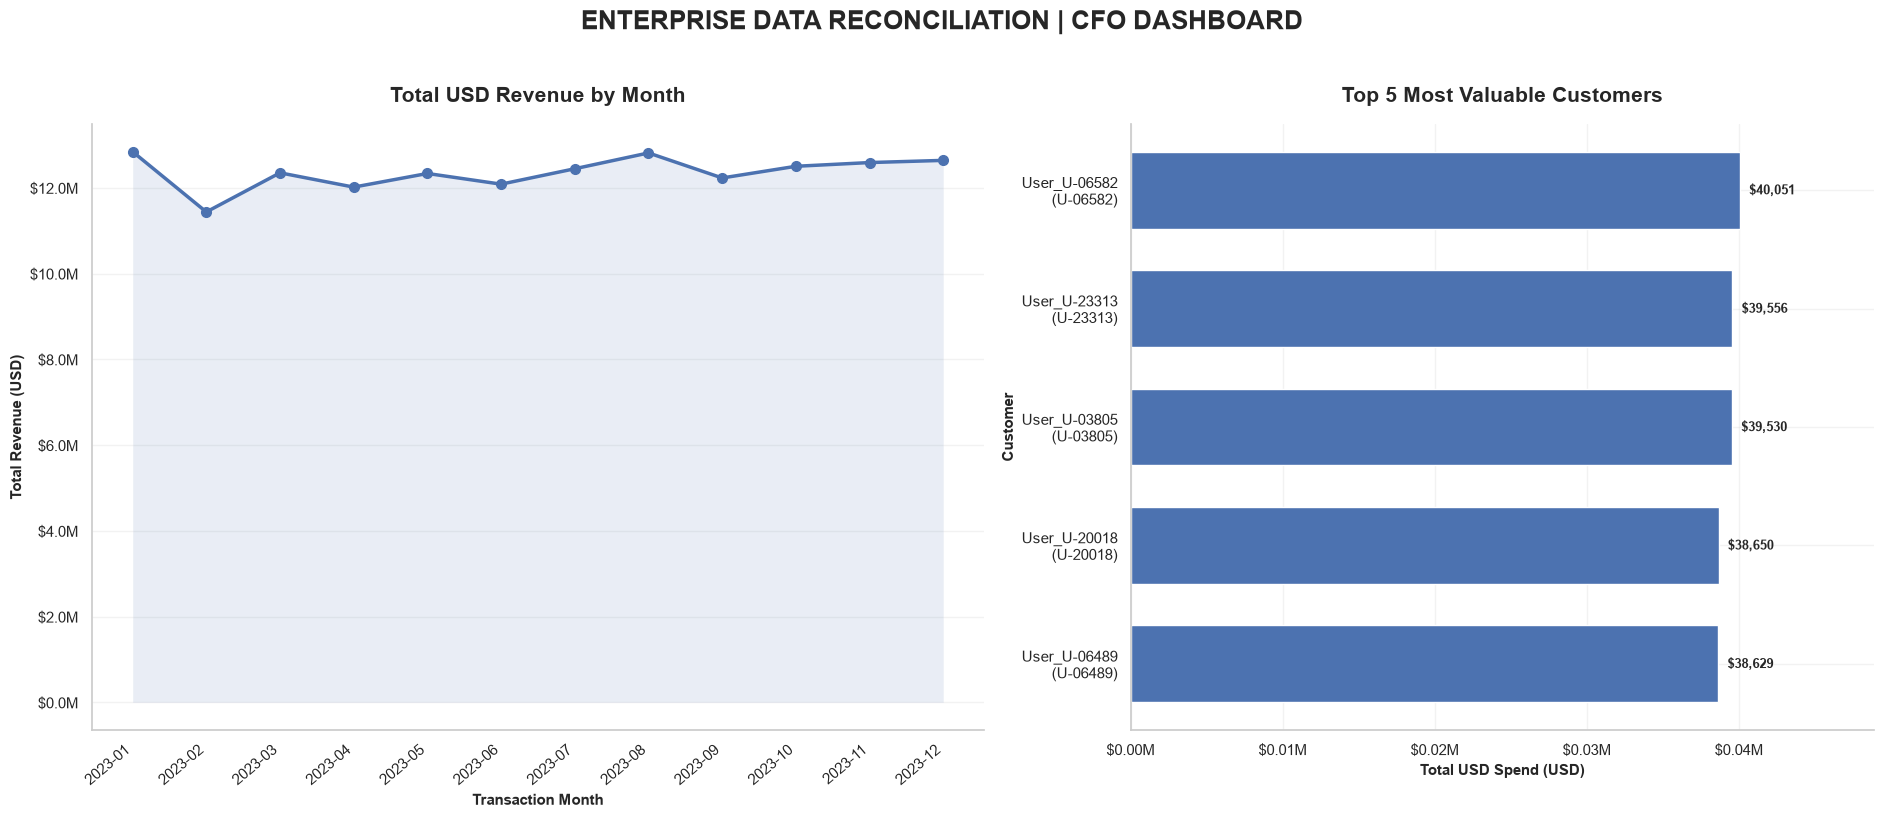


CFO DASHBOARD VALIDATION
Total reconciled USD revenue: $148,274,622.91
Months represented: 12
Customers ranked: 5
Top 5 customer revenue: $196,415.85
Top 5 revenue contribution: 0.13%
Monthly revenue reconciliation: True

PHASE 4 COMPLETED SUCCESSFULLY!


In [9]:

# ================================================================
# PHASE 4: AGGREGATION & VISUALIZATION
# CFO FINANCIAL DASHBOARD
# Project: Enterprise Data Reconciliation
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# ------------------------------------------------
# 1. VERIFY THE FINAL RECONCILED DATA
# ------------------------------------------------

if "df_final" not in globals():
    raise NameError(
        "df_final is not available. Execute Phase 3 first."
    )

required_columns = {
    "Date",
    "User ID",
    "Customer Name",
    "USD_Revenue"
}

missing_columns = required_columns - set(df_final.columns)

if missing_columns:
    raise ValueError(
        f"Required columns missing from df_final: {missing_columns}"
    )

dashboard_data = df_final.copy()

dashboard_data["Date"] = pd.to_datetime(
    dashboard_data["Date"],
    errors="coerce"
)

dashboard_data["USD_Revenue"] = pd.to_numeric(
    dashboard_data["USD_Revenue"],
    errors="coerce"
)

if dashboard_data[list(required_columns)].isna().any().any():
    raise ValueError(
        "Missing or invalid values found in dashboard data."
    )

if dashboard_data.empty:
    raise ValueError(
        "Final reconciled dataset is empty."
    )

if dashboard_data["USD_Revenue"].lt(0).any():
    raise ValueError(
        "Negative revenue values require investigation."
    )

# ------------------------------------------------
# 2. CALCULATE TOTAL USD REVENUE BY MONTH
# ------------------------------------------------

monthly_revenue = (
    dashboard_data.assign(
        Month=dashboard_data["Date"].dt.to_period("M")
    )
    .groupby("Month", as_index=False)
    .agg(
        Total_USD_Revenue=(
            "USD_Revenue",
            "sum"
        ),
        Transaction_Count=(
            "USD_Revenue",
            "size"
        )
    )
    .sort_values("Month")
    .reset_index(drop=True)
)

monthly_revenue["Month_Label"] = (
    monthly_revenue["Month"].astype(str)
)

# ------------------------------------------------
# 3. CALCULATE TOP 5 MOST VALUABLE CUSTOMERS
# ------------------------------------------------

top_5_customers = (
    dashboard_data
    .groupby(
        ["User ID", "Customer Name"],
        as_index=False
    )
    .agg(
        Total_USD_Spend=(
            "USD_Revenue",
            "sum"
        ),
        Transaction_Count=(
            "USD_Revenue",
            "size"
        )
    )
    .sort_values(
        "Total_USD_Spend",
        ascending=False
    )
    .head(5)
    .reset_index(drop=True)
)

top_5_customers.insert(
    0,
    "Rank",
    range(1, len(top_5_customers) + 1)
)

# ------------------------------------------------
# 4. VALIDATE DASHBOARD AGGREGATIONS
# ------------------------------------------------

total_reconciled_revenue = (
    dashboard_data["USD_Revenue"].sum()
)

monthly_revenue_total = (
    monthly_revenue["Total_USD_Revenue"].sum()
)

top_5_revenue = (
    top_5_customers["Total_USD_Spend"].sum()
)

top_5_revenue_share = (
    top_5_revenue / total_reconciled_revenue
)

assert np.isclose(
    total_reconciled_revenue,
    monthly_revenue_total,
    rtol=1e-10,
    atol=0.01
), "Monthly revenue does not reconcile to final revenue."

assert len(top_5_customers) == min(
    5,
    dashboard_data["User ID"].nunique()
), "Top-five customer count is incorrect."

assert top_5_customers[
    "Total_USD_Spend"
].is_monotonic_decreasing, (
    "Top-five customers are not sorted by spending."
)

assert monthly_revenue["Month"].is_monotonic_increasing, (
    "Monthly revenue is not in chronological order."
)

# ------------------------------------------------
# 5. DISPLAY MONTHLY REVENUE SUMMARY
# ------------------------------------------------

print("=" * 60)
print("MONTHLY USD REVENUE SUMMARY")
print("=" * 60)

display(
    monthly_revenue[
        [
            "Month_Label",
            "Transaction_Count",
            "Total_USD_Revenue"
        ]
    ].style.format(
        {
            "Transaction_Count": "{:,.0f}",
            "Total_USD_Revenue": "${:,.2f}"
        }
    )
)

# ------------------------------------------------
# 6. DISPLAY TOP 5 CUSTOMER SUMMARY
# ------------------------------------------------

print("\n" + "=" * 60)
print("TOP 5 MOST VALUABLE CUSTOMERS")
print("=" * 60)

display(
    top_5_customers[
        [
            "Rank",
            "User ID",
            "Customer Name",
            "Transaction_Count",
            "Total_USD_Spend"
        ]
    ].style.format(
        {
            "Transaction_Count": "{:,.0f}",
            "Total_USD_Spend": "${:,.2f}"
        }
    )
)

# ------------------------------------------------
# 7. PREPARE PROFESSIONAL DASHBOARD FORMATTING
# ------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(19, 8),
    gridspec_kw={
        "width_ratios": [1.2, 1]
    }
)

fig.suptitle(
    "ENTERPRISE DATA RECONCILIATION | CFO DASHBOARD",
    fontsize=19,
    fontweight="bold",
    y=1.02
)

# ------------------------------------------------
# 8. CHART 1: TOTAL USD REVENUE BY MONTH
# ------------------------------------------------

month_labels = monthly_revenue[
    "Month_Label"
].tolist()

month_values = monthly_revenue[
    "Total_USD_Revenue"
].to_numpy()

month_positions = np.arange(
    len(month_labels)
)

axes[0].plot(
    month_positions,
    month_values,
    marker="o",
    linewidth=2.5,
    markersize=7
)

axes[0].fill_between(
    month_positions,
    month_values,
    alpha=0.12
)

axes[0].set_title(
    "Total USD Revenue by Month",
    fontsize=15,
    fontweight="bold",
    pad=16
)

axes[0].set_xlabel(
    "Transaction Month",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_ylabel(
    "Total Revenue (USD)",
    fontsize=11,
    fontweight="bold"
)

axes[0].set_xticks(
    month_positions
)

axes[0].set_xticklabels(
    month_labels,
    rotation=40,
    ha="right"
)

axes[0].yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: f"${value / 1_000_000:.1f}M"
    )
)

# ------------------------------------------------
# 9. CHART 2: TOP 5 MOST VALUABLE CUSTOMERS
# ------------------------------------------------

top_5_plot = top_5_customers.sort_values(
    "Total_USD_Spend",
    ascending=True
).copy()

customer_labels = [
    f"{name}\n({user_id})"
    for name, user_id in zip(
        top_5_plot["Customer Name"],
        top_5_plot["User ID"]
    )
]

customer_values = top_5_plot[
    "Total_USD_Spend"
].to_numpy()

bars = axes[1].barh(
    customer_labels,
    customer_values,
    height=0.65
)

axes[1].set_title(
    "Top 5 Most Valuable Customers",
    fontsize=15,
    fontweight="bold",
    pad=16
)

axes[1].set_xlabel(
    "Total USD Spend (USD)",
    fontsize=11,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Customer",
    fontsize=11,
    fontweight="bold"
)

axes[1].xaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: f"${value / 1_000_000:.2f}M"
    )
)

axes[1].set_xlim(
    0,
    max(customer_values) * 1.22
)

# Add customer spending labels.

for bar, value in zip(bars, customer_values):

    axes[1].text(
        value + max(customer_values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"${value:,.0f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

# ------------------------------------------------
# 10. FINAL DASHBOARD LAYOUT
# ------------------------------------------------

for ax in axes:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.25
    )

axes[1].grid(
    axis="x",
    alpha=0.25
)

axes[0].grid(
    axis="x",
    visible=False
)

plt.tight_layout()

plt.show()

# ------------------------------------------------
# 11. FINAL DASHBOARD VALIDATION
# ------------------------------------------------

print("\n" + "=" * 60)
print("CFO DASHBOARD VALIDATION")
print("=" * 60)

print(
    f"Total reconciled USD revenue: "
    f"${total_reconciled_revenue:,.2f}"
)

print(
    "Months represented:",
    len(monthly_revenue)
)

print(
    "Customers ranked:",
    len(top_5_customers)
)

print(
    f"Top 5 customer revenue: "
    f"${top_5_revenue:,.2f}"
)

print(
    f"Top 5 revenue contribution: "
    f"{top_5_revenue_share:.2%}"
)

print(
    "Monthly revenue reconciliation:",
    np.isclose(
        monthly_revenue_total,
        total_reconciled_revenue,
        atol=0.01
    )
)

print("\nPHASE 4 COMPLETED SUCCESSFULLY!")


In [10]:
NOTEBOOK_END_TIME = time.perf_counter()

TOTAL_EXECUTION_TIME = (
    NOTEBOOK_END_TIME - NOTEBOOK_START_TIME
)

print("=" * 55)
print("FINAL NOTEBOOK PERFORMANCE REPORT")
print("=" * 55)

print(f"Total execution time: {TOTAL_EXECUTION_TIME:.2f} seconds")
print(f"Time limit: 120 seconds")

if TOTAL_EXECUTION_TIME < 120:
    print("PERFORMANCE REQUIREMENT: PASSED")
else:
    print("PERFORMANCE REQUIREMENT: NOT PASSED")

FINAL NOTEBOOK PERFORMANCE REPORT
Total execution time: 5.54 seconds
Time limit: 120 seconds
PERFORMANCE REQUIREMENT: PASSED



# ENTERPRISE DATA RECONCILIATION

## 1. Project Overview

### 1.1 Business Context

This project simulates a financial data reconciliation scenario at a FinTech company that sells digital products to customers across Europe.

Customers make purchases in Euros (EUR), while the company's financial reports are prepared in US Dollars (USD).

The Chief Financial Officer (CFO) requires reliable revenue figures for financial reporting and business decision-making.

However, the required information is distributed across multiple systems, including a customer account database, application server logs, and a daily currency exchange-rate dataset.

The objective is to integrate these data sources, resolve data-quality issues, calculate accurate USD revenue, and present meaningful financial insights.

### 1.2 Business Objective

The central business question addressed by this project is:

**How much genuine revenue, in US dollars, did the company earn from its currently active customers, how did revenue change month by month, and which customers generated the highest spending?**

To answer this question, the project focuses on:

- Identifying customers using their most recent account status.
- Extracting successful purchase transactions from unstructured server logs.
- Excluding failed transaction events.
- Converting EUR transaction values into USD using applicable exchange rates.
- Handling dates with missing published exchange rates.
- Reconciling customer, transaction, and financial records.
- Producing monthly revenue analysis and customer rankings.

### 1.3 Data Sources

The project uses three original data sources supplied by Internship Studio.

| Data Source | File | Purpose |
|---|---|---|
| Customer Account Database | enterprise_database.db | Contains customer details and historical account-status records. |
| Application Server Logs | server_logs.txt | Contains successful and failed application events, including transaction information. |
| Daily Exchange Rates | daily_exchange_rates.csv | Contains daily EUR-to-USD exchange-rate information. |

### 1.4 Technology Stack

The following technologies and libraries are used:

- **Python:** Main programming language for the analytical workflow.
- **Pandas:** Data inspection, manipulation, extraction, merging, and aggregation.
- **SQLite:** Relational database access and SQL-based customer extraction.
- **Regular Expressions (Regex):** Extraction of structured transaction information from raw log text.
- **Matplotlib:** Financial data visualization.
- **Seaborn:** Dashboard styling and visualization support.
- **Jupyter Notebook:** Interactive development, analysis, documentation, and reporting.

### 1.5 Project Workflow

The project follows four major analytical phases:

1. **SQL Customer Extraction:** Identify customers whose latest account status is Active.
2. **Regex and Data Extraction:** Extract successful transaction details from server logs.
3. **Financial Reconciliation and Merging:** Integrate transactions, customer information, and exchange rates to calculate USD revenue.
4. **Aggregation and Visualization:** Analyze monthly revenue and identify the five most valuable customers.

### 1.6 Expected Deliverables

The completed notebook is designed to produce the following required analytical outputs:

- `df_active_users` — currently active customer records.
- `extracted_data` — structured successful transaction records.
- `df_final` — reconciled transaction records containing USD revenue.
- Monthly USD revenue summary.
- Top five most valuable customer summary.
- CFO financial dashboard containing two visualizations.
- Data-quality observations, reconciliation decisions, and validation results.

### 1.7 Scope and Data Considerations

All calculations and conclusions are based on the original datasets supplied for this assessment.

Data-quality issues, missing exchange rates, historical account statuses, and excluded failed events are investigated and documented during the analytical process.

The results represent the information available in the supplied datasets and should be interpreted within their data coverage and limitations.



## 2. Phase 1 — SQL Customer Extraction

### 2.1 Objective

The objective of this phase is to identify customers whose most recent account status is Active.

The customer database contains historical account records. A single customer may have multiple records because their account status can change over time.

Therefore, selecting every record with an Active status would produce incorrect results. Only the latest status record for each customer should be considered.

### 2.2 Database Exploration

The SQLite database contains a table named `users` with the following columns:

| Column | Description |
|---|---|
| user_id | Unique customer identifier |
| name | Customer name |
| status | Customer account status |
| updated_at | Date and time of the status update |

The original database contains 47,464 records representing 25,000 unique customers.

### 2.3 SQL Methodology

The SQL `ROW_NUMBER()` window function was used to identify the latest record for each customer.

The query uses:

- `PARTITION BY user_id` to group records by customer.
- `ORDER BY datetime(updated_at) DESC` to rank the most recent update first.
- `ROW_NUMBER()` to assign a sequential rank to each customer's records.
- `WHERE rn = 1` to select the latest record.
- `status = 'Active'` to retain only currently active customers according to the supplied database.

A secondary `rowid DESC` ordering was included to provide a deterministic tie-breaker when update timestamps are identical.

The SQL result was loaded into a Pandas DataFrame named `df_active_users`.

### 2.4 Results and Findings

The SQL extraction identified the following latest account-status distribution:

| Latest Account Status | Number of Customers |
|---|---:|
| Active | 14,183 |
| Pending | 5,935 |
| Suspended | 4,882 |
| **Total** | **25,000** |

A total of 14,183 customers were identified as Active and retained for further financial analysis.

### 2.5 Validation

The following checks were performed:

- Verified that the extracted customer IDs are unique.
- Confirmed that every extracted record has an Active status.
- Compared the extracted active-customer count with the SQL status summary.
- Reconciled the latest status counts against the 25,000 unique customers in the source database.

The validation confirmed 14,183 unique active customers with zero duplicate customer IDs.

### 2.6 Data Limitation

The latest account-status update available in the supplied database is February 28, 2023.

Therefore, the extracted customer statuses represent the latest information available in the supplied dataset, not independently verified present-day account statuses.

### 2.7 Phase 1 Conclusion

The historical customer records were successfully analysed using SQLite window functions. The latest account status was identified for each customer, and 14,183 active customers were extracted into `df_active_users`.

The resulting DataFrame was validated and prepared for the subsequent transaction extraction and financial reconciliation phases.



## 3. Phase 2 — Regex and Unstructured Data Extraction

### 3.1 Objective

The objective of this phase is to extract structured transaction information from the unstructured application server logs.

The supplied server-log file contains 100,000 event records. Transaction information is embedded inside text strings rather than being provided in separate columns.

The required information includes transaction date, customer ID, product ID, and transaction amount in EUR.

### 3.2 Server Log Exploration

The original server-log file contains a column named `Raw_Server_Log`.

Each record contains a timestamp, an event classification, a transaction message, and a payload containing transaction details.

Two types of events were identified:

- INFO: Successful transaction events.
- ERROR: Failed transaction events.

The failed events contain a `failed_val` field instead of the successful transaction amount field `eur_val`.

### 3.3 Data Extraction Methodology

Pandas was used to load and inspect the server-log file.

Regular Expressions (Regex) and Pandas string extraction methods were used to identify and extract the required information.

The extraction process involved:

1. Loading the server logs into a Pandas Series.
2. Identifying INFO and ERROR events.
3. Excluding records classified as ERROR.
4. Extracting the transaction timestamp.
5. Extracting the customer ID from the `u` field.
6. Extracting the product ID from the `item_code` field.
7. Extracting the successful transaction amount from the `eur_val` field.
8. Combining the extracted fields into a structured DataFrame named `extracted_data`.

### 3.4 Extracted Data Structure

The resulting DataFrame contains the following columns:

| Column | Description |
|---|---|
| Date | Transaction date and timestamp |
| User ID | Unique customer identifier |
| Product ID | Product identifier |
| Euro Value | Successful transaction amount in EUR |

The Date column was converted into a datetime data type, and the Euro Value column was converted into a numeric data type.

### 3.5 Data Cleaning Results

The server-log classification produced the following results:

| Metric | Records |
|---|---:|
| Total raw log records | 100,000 |
| Successful INFO events | 94,902 |
| Failed ERROR events excluded | 5,098 |
| Unclassified events | 0 |
| Parsing failures | 0 |
| **Successfully extracted transactions** | **94,902** |

All successful INFO records were successfully parsed into structured transaction records.

### 3.6 Additional Data Quality Findings

Further inspection of the extracted transactions identified:

| Metric | Result |
|---|---:|
| Unique transaction customers | 24,466 |
| Unique product IDs | 900 |
| Exact duplicate transaction rows | 0 |
| Earliest transaction | 01 January 2023 |
| Latest transaction | 31 December 2023 |

No exact duplicate rows were identified across the four extracted transaction fields.

Repeated purchases were retained because identical extracted fields do not necessarily represent duplicate business transactions.

### 3.7 Validation

The following validation checks were performed:

- Confirmed that all 100,000 raw log events were classified.
- Verified that 5,098 ERROR events were excluded.
- Confirmed that no successful records were left unclassified.
- Checked that all successful INFO records were extracted.
- Validated customer ID and product ID formats.
- Verified that transaction dates and euro amounts had the appropriate data types.
- Confirmed that no parsing failures or missing extracted fields remained.

The extracted transaction count of 94,902 matched the number of successful INFO events.

### 3.8 Phase 2 Conclusion

The unstructured application server logs were successfully processed using Pandas string operations and Regular Expressions.

A total of 94,902 successful transaction records were extracted into `extracted_data`, while 5,098 failed events were excluded.

The structured transaction dataset was validated and prepared for the financial reconciliation and merging phase.



## 4. Phase 3 — Financial Reconciliation and Merging

### 4.1 Objective

The objective of this phase is to integrate the extracted transaction records, customer information, and daily EUR-to-USD exchange rates to calculate genuine revenue generated by currently active customers.

The reconciliation process ensures that valid transactions are retained during the exchange-rate merge and that only customers whose latest available account status is Active are included in the final revenue analysis.

### 4.2 Exchange Rate Data Preparation

The daily exchange-rate CSV contains 365 calendar dates.

Initial inspection identified:

| Metric | Result |
|---|---:|
| Total calendar dates | 365 |
| Published exchange rates | 261 |
| Missing published exchange rates | 104 |
| Missing Friday rates | 52 |
| Missing Saturday rates | 52 |
| Missing Sunday rates | 0 |

The missing-rate pattern in the actual dataset differs from the weekend pattern described in the supporting project document.

Therefore, the actual CSV was inspected before selecting the treatment method.

### 4.3 Missing Exchange Rate Treatment

The Pandas forward-fill method (`ffill`) was used to populate missing exchange rates using the most recent previously published rate.

The original exchange-rate column, `EUR_to_USD`, was preserved.

A separate column, `EUR_to_USD_Filled`, was created to store the rates used for financial reconciliation.

This approach ensures that transaction dates with missing published rates can still be matched to an available previous rate without silently losing valid transactions.

A total of 26,984 successful transactions occurred on dates with missing published exchange rates.

All these transactions successfully received a usable exchange rate through forward-filling.

### 4.4 Transaction and Exchange Rate Integration

The successful transaction DataFrame, `extracted_data`, was merged with the prepared exchange-rate dataset using the transaction date.

The integration process included:

- Converting transaction dates into a consistent datetime format.
- Normalizing dates to calendar-day precision.
- Sorting exchange-rate records chronologically.
- Preserving original and forward-filled exchange rates.
- Matching transactions to the exchange-rate calendar using a left join.
- Validating that each transaction matched exactly one calendar date.

The left join ensured that all successful transactions were retained during the exchange-rate reconciliation stage.

### 4.5 Active Customer Integration

After exchange-rate reconciliation, the transaction records were checked against the active customer DataFrame, `df_active_users`.

The customer database was also checked to verify that transaction customer IDs existed in the source database.

An inner join was used to retain only transactions belonging to customers whose latest available account status was Active.

Transactions belonging to customers with Pending or Suspended latest statuses were excluded from the final revenue dataset.

No unknown customer IDs were identified.

### 4.6 USD Revenue Calculation

USD revenue was calculated using the following formula:

**USD Revenue = Euro Value × EUR-to-USD Exchange Rate**

The calculation uses the prepared `EUR_to_USD_Filled` column.

The resulting revenue values were stored in a new column named `USD_Revenue`.

The calculation retained numerical precision, while final monetary totals were formatted to two decimal places for reporting.

### 4.7 Transaction Reconciliation Results

The financial reconciliation produced the following results:

| Reconciliation Metric | Actual Result |
|---|---:|
| Successful extracted transactions | 94,902 |
| Transactions matched to exchange-rate calendar | 94,902 |
| Transactions on missing-rate dates | 26,984 |
| Unmatched transaction dates | 0 |
| Remaining missing filled rates | 0 |
| Active customers available | 14,183 |
| Transactions belonging to active customers | 53,899 |
| Transactions excluded for inactive customers | 41,003 |
| Transactions with unknown customer IDs | 0 |
| Active customers with transactions | 13,888 |
| Final reconciled transaction rows | 53,899 |

### 4.8 Final Financial Result

The total reconciled USD revenue generated by transactions belonging to currently active customers was:

**Total USD Revenue: $148,274,622.91**

The final DataFrame, `df_final`, contains 53,899 reconciled transaction records.

It includes customer information, transaction dates, product identifiers, EUR transaction values, original exchange rates, forward-filled exchange rates, and calculated USD revenue.

No missing USD revenue values remained in the final dataset.

### 4.9 Validation and Data Quality Checks

The following checks were performed:

- Verified the completeness of the exchange-rate calendar.
- Checked for duplicate exchange-rate dates.
- Confirmed that all missing exchange rates were filled.
- Verified that all 94,902 successful transactions matched the exchange-rate calendar.
- Confirmed that no transactions were lost or multiplied during the exchange-rate merge.
- Checked transaction customer IDs against the source customer database.
- Verified that only Active customers were retained in the final dataset.
- Reconciled active and inactive customer transaction counts.
- Confirmed that all final USD revenue values were present and valid.

The transaction reconciliation and customer validation checks passed successfully.

### 4.10 Data Limitations and Assumptions

The supplied exchange-rate dataset contains missing published rates on Fridays and Saturdays rather than the Saturday and Sunday pattern described in the supporting document.

Forward-filling was applied using the most recent previously published rate. This is an analytical assumption for the assessment and does not independently establish the officially applicable financial-market rate for every missing date.

The customer database contains account-status history only up to February 28, 2023. Consequently, the analysis uses the latest status available in the supplied database rather than independently verified present-day customer statuses.

### 4.11 Phase 3 Conclusion

The three data sources were successfully integrated using Pandas and SQLite-derived customer information.

Missing exchange rates were handled using forward-filling, successful transactions were retained during rate reconciliation, and transactions belonging to inactive customers were excluded.

The final reconciled dataset contained 53,899 transactions from 13,888 active customers, generating total USD revenue of $148,274,622.91.

The validated DataFrame, `df_final`, was prepared for the final CFO dashboard and business analysis phase.



## 5. Phase 4 — Aggregation, Visualization and CFO Dashboard

### 5.1 Objective

The objective of this phase is to transform the reconciled financial data into meaningful business information through aggregation and visualization.

The final dataset, `df_final`, was used to prepare two financial views:

- Total USD revenue generated each month.
- The five customers with the highest total USD spending.

These visualizations provide the CFO with a clear overview of revenue performance and customer spending.

### 5.2 Monthly Revenue Analysis

Monthly revenue was calculated by grouping the final reconciled transactions by transaction month and summing the `USD_Revenue` column.

The analysis covers all twelve months of 2023.

| Month | Total USD Revenue |
|---|---:|
| January | $12,841,761.38 |
| February | $11,436,130.90 |
| March | $12,348,931.84 |
| April | $12,015,376.19 |
| May | $12,333,644.45 |
| June | $12,084,355.82 |
| July | $12,444,163.58 |
| August | $12,812,730.66 |
| September | $12,228,952.05 |
| October | $12,501,330.36 |
| November | $12,588,223.09 |
| December | $12,639,022.60 |

### 5.3 Monthly Revenue Findings

The monthly analysis identified the following observations:

- January recorded the highest monthly revenue of $12,841,761.38.
- February recorded the lowest monthly revenue of $11,436,130.90.
- Revenue increased after February and remained within a relatively narrow range during the remaining months.
- December generated $12,639,022.60 in reconciled USD revenue.

The monthly revenue line chart provides a visual representation of these changes throughout the year.

### 5.4 Top Five Most Valuable Customers

Customer spending was calculated by grouping the final reconciled transactions by customer ID and customer name and summing their total USD revenue.

The five highest-spending customers were identified using descending order of total USD spend.

| Rank | Customer ID | Transactions | Total USD Spend |
|---:|---|---:|---:|
| 1 | U-06582 | 12 | $40,050.99 |
| 2 | U-23313 | 11 | $39,555.81 |
| 3 | U-03805 | 11 | $39,529.95 |
| 4 | U-20018 | 8 | $38,649.97 |
| 5 | U-06489 | 9 | $38,629.14 |

### 5.5 Customer Spending Findings

The customer ranking identified five customers with the highest reconciled USD spending.

The main observations are:

- Customer U-06582 ranked first with total spending of $40,050.99 across 12 transactions.
- Customer U-23313 ranked second with $39,555.81.
- Customer U-03805 ranked third with $39,529.95.
- The top five customers generated a combined USD spend of $196,415.85.
- Their combined contribution represented approximately 0.13% of total reconciled USD revenue.

The horizontal bar chart provides a comparison of spending among these five customers.

### 5.6 CFO Dashboard Development

Two visualizations were created using Matplotlib and Seaborn.

**Chart 1 — Total USD Revenue by Month**

A line chart was developed to display monthly revenue trends across the twelve months of 2023.

It includes a chart title, transaction-month labels, USD revenue axis labels, and readable currency formatting.

**Chart 2 — Top 5 Most Valuable Customers**

A horizontal bar chart was developed to compare the five highest-spending customers.

It includes customer identifiers, total USD spending labels, and a clear ranking based on descending customer revenue.

Both visualizations were arranged side by side to create a consolidated CFO dashboard.

### 5.7 Dashboard Validation

The following validation checks were performed:

- Confirmed that monthly revenue aggregation covers all twelve months.
- Verified that exactly five customers were selected for ranking.
- Checked that customer spending was sorted in descending order.
- Confirmed that the sum of monthly revenue matches the total reconciled USD revenue within the displayed currency precision.
- Compared the dashboard's total revenue against the Phase 3 reconciliation result.

The dashboard validation confirmed total reconciled USD revenue of $148,274,622.91 and successful monthly revenue reconciliation.

### 5.8 Key Business Insights

Based on the completed analysis, the following business insights were identified:

1. The company generated $148,274,622.91 in reconciled USD revenue from transactions belonging to customers classified as Active using the latest available account records.
2. January recorded the highest monthly revenue, while February recorded the lowest.
3. Revenue remained relatively consistent across the remaining months of the analysis period.
4. Customer U-06582 was the highest-spending customer among the active-customer transactions.
5. The five highest-spending customers together contributed approximately 0.13% of total reconciled revenue, indicating that revenue was distributed across a much broader customer base in this dataset.

### 5.9 Business Recommendations

Based on the findings, the following actions are recommended:

- Monitor monthly revenue performance to identify changes and potential fluctuations.
- Investigate the reasons behind February's lower revenue before introducing corrective business measures.
- Maintain customer-level revenue reporting to understand purchasing activity and identify high-value customers.
- Strengthen exchange-rate data quality and maintain a documented policy for dates without published rates.
- Ensure that customer account-status information is updated regularly so financial reporting uses timely customer records.

These recommendations are based on the observed results and should be investigated further before any major business decisions are made.

### 5.10 Project Conclusion

The Enterprise Data Reconciliation project successfully integrated customer account records, application server logs, and daily exchange-rate information into a reconciled financial dataset.

The analytical process included SQL-based customer extraction, Regex-based transaction extraction, missing exchange-rate handling, customer and transaction reconciliation, USD revenue calculation, and financial visualization.

The final dataset contained 53,899 reconciled transactions from 13,888 customers classified as Active using the latest available customer records.

The total reconciled USD revenue was $148,274,622.91.

The project also produced a monthly revenue analysis and a ranking of the five most valuable customers.

The completed CFO dashboard provides a consolidated view of financial performance and customer spending based on the supplied assessment datasets.

The results and business findings are subject to the data coverage and assumptions documented in this notebook.
